**Task 1: Data Preparation and Feature Engineering**

In [1]:
# import all required libraries
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# import all required libraries
import sys
from importlib.metadata import version

# record python and package versions for reproducibility
package_names = [
    'pandas',
    'numpy',
    'yfinance',
    'matplotlib',
    'seaborn',
    'scipy',
    'scikit-learn'
]

package_versions = pd.DataFrame([
    {'Package': 'python', 'Version': sys.version.split()[0]},
    *[
        {'Package': name, 'Version': version(name)}
        for name in package_names
    ]
])

display(package_versions)

,Package,Version
0,python,3.13.18
1,pandas,2.2.3
2,numpy,2.4.6
3,yfinance,0.2.66
4,matplotlib,3.10.0
5,seaborn,0.13.2
6,scipy,1.16.3
7,scikit-learn,1.6.1


In [3]:
# part 1: extract s&p 500 tickers from wikipedia using pandas
# user-agent is required to avoid http 403 blocking from wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
sp500_df = table[0]

tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]

retrieval_date = pd.Timestamp.now(tz='Asia/Colombo').date()
sp500_df['Retrieval Date'] = retrieval_date
sp500_df['Yahoo Ticker'] = tickers

sp500_df.to_csv('sp500_tickers.csv', index=False)

print('Total tickers extracted:', len(tickers))
print('Retrieval date:', retrieval_date)
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

Total tickers extracted: 503
Retrieval date: 2026-11-25


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [4]:
# part 2: download daily market data via yfinance
# period: 01-01-2021 to 01-01-2025 | daily prices, adjusted prices, volume and corporate actions
start = '2021-01-01'
end = '2025-01-01'

download_tickers = tickers + ['^GSPC']

daily_data = yf.download(
    download_tickers,
    start=start,
    end=end,
    auto_adjust=False,
    actions=True,
    progress=False
)

print('Shape:', daily_data.shape)
print('Date range:', daily_data.index.min(), 'to', daily_data.index.max())
daily_data.head()

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['FDXF', 'SNDK', 'Q', 'VYLR', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Shape: (1005, 4022)
Date range: 2021-01-04 00:00:00 to 2024-12-31 00:00:00


Price        Adj Close                                                \
Ticker               A        AAPL       ABBV        ABNB        ABT   
Date                                                                   
2021-01-04  114.009117  125.537132  84.219139  139.149994  97.269691   
2021-01-05  114.941254  127.089256  85.090012  148.300003  98.473198   
2021-01-06  118.093239  122.811218  84.354965  142.770004  98.268158   
2021-01-07  121.235603  127.001938  85.257805  151.270004  99.222054   
2021-01-08  122.100479  128.098083  85.705223  149.770004  99.498413   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  33.186359  232.029327  485.339996  132.622620  42.189491  ...   
2021-01-05  33.319485  233.350296  485.690002  134.993149  43.010090  ...   
2021-01-06  34.783871  235.901566  466.309998  135.601700  44.752838  ...   
2021-01-07  34.460564  238.127289  477.739990  141.332733  44.355217  ...   
2021-01-08  34.650742  238.995850  485.100006  142.359070  44.473656  ...   

Price        Volume                                                          \
Ticker         WYNN      XEL       XOM      XYL       XYZ      YUM      ZBH   
Date                                                                          
2021-01-04  3596800  3197100  27764700   814700   9838400  2058200  1265870   
2021-01-05  1814600  1976800  44035100  1005200   9699400  1475300   998894   
2021-01-06  2433700  2667000  36484800  1015300  12003500  1352700  1424799   
2021-01-07  3846700  2630400  29528100  1539300  10214200  2222900  1237648   
2021-01-08  2812400  2221500  28628200  1632200   9102100  1252200  1259072   

Price                                    
Ticker        ZBRA      ZTS       ^GSPC  
Date                                     
2021-01-04  432600  1805900  5015000000  
2021-01-05  374700  1358600  4591020000  
2021-01-06  419500  2139800  6064110000  
2021-01-07  379900  1710700  5099160000  
2021-01-08  348500  1475900  4773040000  

[5 rows x 4022 columns]

In [5]:
# part 2.1: mask ticker data from before nyse trading began
if 'downloaded_daily_data' not in globals():
    downloaded_daily_data = daily_data.copy()

daily_data = downloaded_daily_data.copy()

nyse_start_dates = {
    'SW': '2024-07-08',
    'FERG': '2021-03-08'
}

market_fields = [
    'Open', 'High', 'Low', 'Close', 'Adj Close',
    'Volume', 'Dividends', 'Stock Splits'
]

for ticker, first_nyse_date in nyse_start_dates.items():
    before_listing = daily_data.index < pd.Timestamp(first_nyse_date)

    for field in market_fields:
        if field in daily_data.columns.get_level_values(0):
            daily_data.loc[before_listing, (field, ticker)] = np.nan

    print(
        ticker,
        'pre-listing rows masked:',
        int(before_listing.sum()),
        '| first NYSE date:',
        first_nyse_date
    )

SW pre-listing rows masked: 881 | first NYSE date: 2024-07-08
FERG pre-listing rows masked: 43 | first NYSE date: 2021-03-08


In [6]:
# part 3: inspect downloaded data before validation
print('Column levels:', daily_data.columns.names)
print('Available fields:', daily_data.columns.get_level_values(0).unique().tolist())
print('Date range:', daily_data.index.min(), 'to', daily_data.index.max())
print('Duplicate dates:', daily_data.index.duplicated().sum())

for field in ['Close', 'Adj Close', 'Volume']:
    if field in daily_data.columns.get_level_values(0):
        field_data = daily_data[field]
        missing = field_data.isna().sum().sort_values(ascending=False)
        print(f'\nMissing values in {field} (highest 10):')
        print(missing.head(10))

daily_data.head()

Column levels: ['Price', 'Ticker']
Available fields: ['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']
Date range: 2021-01-04 00:00:00 to 2024-12-31 00:00:00
Duplicate dates: 0

Missing values in Close (highest 10):
Ticker
HONA    1005
Q       1005
FDXF    1005
SNDK    1005
VYLR    1005
SW       881
GEV      812
SOLV     811
RDDT     808
VLTO     692
dtype: int64

Missing values in Adj Close (highest 10):
Ticker
HONA    1005
Q       1005
FDXF    1005
SNDK    1005
VYLR    1005
SW       881
GEV      812
SOLV     811
RDDT     808
VLTO     692
dtype: int64

Missing values in Volume (highest 10):
Ticker
HONA    1005
Q       1005
FDXF    1005
SNDK    1005
VYLR    1005
SW       881
GEV      812
SOLV     811
RDDT     808
VLTO     692
dtype: int64


Price        Adj Close                                                \
Ticker               A        AAPL       ABBV        ABNB        ABT   
Date                                                                   
2021-01-04  114.009117  125.537132  84.219139  139.149994  97.269691   
2021-01-05  114.941254  127.089256  85.090012  148.300003  98.473198   
2021-01-06  118.093239  122.811218  84.354965  142.770004  98.268158   
2021-01-07  121.235603  127.001938  85.257805  151.270004  99.222054   
2021-01-08  122.100479  128.098083  85.705223  149.770004  99.498413   

Price                                                                 ...  \
Ticker           ACGL         ACN        ADBE         ADI        ADM  ...   
Date                                                                  ...   
2021-01-04  33.186359  232.029327  485.339996  132.622620  42.189491  ...   
2021-01-05  33.319485  233.350296  485.690002  134.993149  43.010090  ...   
2021-01-06  34.783871  235.901566  466.309998  135.601700  44.752838  ...   
2021-01-07  34.460564  238.127289  477.739990  141.332733  44.355217  ...   
2021-01-08  34.650742  238.995850  485.100006  142.359070  44.473656  ...   

Price        Volume                                                          \
Ticker         WYNN      XEL       XOM      XYL       XYZ      YUM      ZBH   
Date                                                                          
2021-01-04  3596800  3197100  27764700   814700   9838400  2058200  1265870   
2021-01-05  1814600  1976800  44035100  1005200   9699400  1475300   998894   
2021-01-06  2433700  2667000  36484800  1015300  12003500  1352700  1424799   
2021-01-07  3846700  2630400  29528100  1539300  10214200  2222900  1237648   
2021-01-08  2812400  2221500  28628200  1632200   9102100  1252200  1259072   

Price                                    
Ticker        ZBRA      ZTS       ^GSPC  
Date                                     
2021-01-04  432600  1805900  5015000000  
2021-01-05  374700  1358600  4591020000  
2021-01-06  419500  2139800  6064110000  
2021-01-07  379900  1710700  5099160000  
2021-01-08  348500  1475900  4773040000  

[5 rows x 4022 columns]

In [7]:
# part 4: check data quality and corporate actions
for field in ['Close', 'Adj Close', 'Volume']:
    field_data = daily_data[field]

    print(f'\n{field}')
    print('Missing values:', int(field_data.isna().sum().sum()))

    if field in ['Close', 'Adj Close']:
        print('Nonpositive values:', int((field_data <= 0).sum().sum()))
    else:
        print('Zero values:', int((field_data == 0).sum().sum()))
        print('Negative values:', int((field_data < 0).sum().sum()))

adjusted_price_history = daily_data['Adj Close'].notna().sum()

print('\nAdjusted-price history by ticker')
print('Fewest available dates:', int(adjusted_price_history.min()))
print('Most available dates:', int(adjusted_price_history.max()))
print('Tickers with the fewest dates:')
print(adjusted_price_history.sort_values().head(10))

for field in ['Dividends', 'Stock Splits']:
    if field in daily_data.columns.get_level_values(0):
        actions = daily_data[field]
        print(f'\nNonzero {field} entries:', int((actions.fillna(0) != 0).sum().sum()))


Close
Missing values: 10135
Nonpositive values: 0

Adj Close
Missing values: 10135
Nonpositive values: 0

Volume
Missing values: 10135
Zero values: 1
Negative values: 0

Adjusted-price history by ticker
Fewest available dates: 0
Most available dates: 1005
Tickers with the fewest dates:
Ticker
VYLR      0
SNDK      0
Q         0
HONA      0
FDXF      0
SW      124
GEV     193
SOLV    194
RDDT    197
VLTO    313
dtype: int64

Nonzero Dividends entries: 6079

Nonzero Stock Splits entries: 61


In [8]:
# part 5: calculate weekly returns using friday-ending weeks
adjusted_prices = daily_data['Adj Close']

first_incomplete_week = pd.Timestamp(start).to_period('W-FRI').end_time.normalize()
last_day = pd.Timestamp(end) - pd.Timedelta(days=1)
last_incomplete_week = last_day.to_period('W-FRI').end_time.normalize()

weekly_prices = adjusted_prices.resample('W-FRI').last()
weekly_prices = weekly_prices.loc[
    (weekly_prices.index > first_incomplete_week) &
    (weekly_prices.index < last_incomplete_week)
]

weekly_returns = weekly_prices.pct_change(fill_method=None)
weekly_returns = weekly_returns.dropna(how='all')

print('Weekly return shape:', weekly_returns.shape)
print('First week label:', weekly_returns.index.min())
print('Last week label:', weekly_returns.index.max())
weekly_returns.head()

Weekly return shape: (207, 504)
First week label: 2021-01-15 00:00:00
Last week label: 2024-12-27 00:00:00


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS,^GSPC
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-15,-0.006690,-0.037183,0.042348,0.130200,0.001240,-0.048024,-0.036505,-0.055700,0.006444,-0.007038,...,-0.025681,-0.012165,0.053454,-0.036133,-0.056741,-0.004946,0.007361,0.009249,-0.038963,-0.014754
2021-01-22,0.000951,0.093833,0.003076,0.074437,0.013837,-0.039781,0.004416,0.031348,-0.013756,0.011877,...,0.011485,-0.003079,-0.009605,-0.008696,-0.021383,0.004408,0.005558,-0.000929,0.012523,0.019431
2021-01-29,-0.048761,-0.051125,-0.075591,0.009677,0.095268,-0.057040,-0.050438,-0.028935,-0.053027,-0.053200,...,-0.073709,-0.011890,-0.054607,-0.058577,-0.031048,-0.052293,-0.045587,-0.051389,-0.055593,-0.033120
2021-02-05,0.025048,0.037923,0.060988,0.063606,0.003560,0.076090,0.048032,0.072694,0.009706,0.065787,...,0.175424,-0.008595,0.113961,0.016565,0.113076,0.037935,0.040476,0.049713,0.032609,0.046467
2021-02-12,0.038967,-0.010163,-0.039455,0.088936,0.033863,0.039941,0.015500,0.013655,0.080801,0.052711,...,0.007351,-0.029950,0.028588,0.009471,0.134662,0.006033,0.009320,0.173491,0.046647,0.012349


In [9]:
# part 6: calculate mean weekly return and weekly beta
market_weekly_returns = weekly_returns['^GSPC']
share_weekly_returns = weekly_returns.drop(columns='^GSPC')

feature_results = []

for share in share_weekly_returns.columns:
    paired_returns = pd.concat(
        [
            share_weekly_returns[share].rename('share'),
            market_weekly_returns.rename('market')
        ],
        axis=1
    ).replace([np.inf, -np.inf], np.nan).dropna()

    market_variance = paired_returns['market'].var(ddof=1)
    weekly_beta = np.nan

    if len(paired_returns) >= 2 and market_variance > 0:
        weekly_beta = (
            paired_returns['share'].cov(paired_returns['market'])
            / market_variance
        )

    feature_results.append({
        'Share': share,
        'Mean_Weekly_Return': paired_returns['share'].mean(),
        'Weekly_Beta': weekly_beta,
        'Aligned_Weeks': len(paired_returns)
    })

return_beta_df = pd.DataFrame(feature_results).set_index('Share')

print('Shares with calculated features:', len(return_beta_df))
return_beta_df.head()

Shares with calculated features: 503


,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks
Share,,,
A,0.001121,1.074724,207
AAPL,0.003930,1.174835,207
ABBV,0.003749,0.425365,207
ABNB,0.001475,1.472709,207
ABT,0.000971,0.583543,207


In [10]:
# part 7: validate ticker histories and set the observation date
raw_close = daily_data['Close'][tickers]
raw_adjusted_prices = daily_data['Adj Close'][tickers]
raw_volume = daily_data['Volume'][tickers]

latest_date = daily_data.index.max()
complete_data = (
    raw_close.notna()
    & (raw_close > 0)
    & raw_volume.notna()
)

available_tickers = complete_data.sum(axis=1)
missing_on_latest_date = complete_data.columns[
    ~complete_data.loc[latest_date]
]

candidate_audit = pd.DataFrame(index=missing_on_latest_date)
candidate_audit['Close observations'] = raw_close[missing_on_latest_date].count()
candidate_audit['Adjusted Close observations'] = (
    raw_adjusted_prices[missing_on_latest_date].count()
)
candidate_audit['Volume observations'] = raw_volume[missing_on_latest_date].count()
candidate_audit['Last Close date'] = raw_close[missing_on_latest_date].apply(
    lambda column: column.last_valid_index()
)
candidate_audit['Last Volume date'] = raw_volume[missing_on_latest_date].apply(
    lambda column: column.last_valid_index()
)

no_history = (
    candidate_audit[
        ['Close observations', 'Adjusted Close observations', 'Volume observations']
    ].sum(axis=1) == 0
)

excluded_tickers = candidate_audit.index[no_history].tolist()
included_tickers = [ticker for ticker in tickers if ticker not in excluded_tickers]

exclusion_log = pd.DataFrame({
    'Ticker': excluded_tickers,
    'Reason': ['no price or volume observations in the study period'] * len(excluded_tickers)
})

close_prices = raw_close[included_tickers]
adjusted_prices = raw_adjusted_prices[included_tickers]
share_volume = raw_volume[included_tickers]

complete_for_observation = (
    close_prices.notna()
    & (close_prices > 0)
    & adjusted_prices.notna()
    & (adjusted_prices > 0)
    & share_volume.notna()
).all(axis=1)

study_period = (
    (daily_data.index >= pd.Timestamp(start))
    & (daily_data.index < pd.Timestamp(end))
)

common_dates = daily_data.index[complete_for_observation & study_period]
observation_date = common_dates.max() if len(common_dates) > 0 else None

print('Included tickers:', len(included_tickers))
print('Excluded tickers:', len(excluded_tickers))
print('Observation date:', observation_date)
print('\nExclusion log:')
exclusion_log

Included tickers: 498
Excluded tickers: 5
Observation date: 2024-12-31 00:00:00

Exclusion log:


,Ticker,Reason
0,FDXF,no price or volume observations in the study p...
1,HONA,no price or volume observations in the study p...
2,Q,no price or volume observations in the study p...
3,SNDK,no price or volume observations in the study p...
4,VYLR,no price or volume observations in the study p...


In [11]:
# part 8: calculate recency from the latest high-volume event
study_volume = daily_data['Volume'][included_tickers].loc[
    (daily_data.index >= pd.Timestamp(start))
    & (daily_data.index <= observation_date)
]

preceding_20_mean = study_volume.rolling(
    window=20,
    min_periods=20
).mean().shift(1)

# flag events against the shifted prior-session average
high_volume_events = study_volume > (2 * preceding_20_mean)

recency_results = []

for share in included_tickers:
    event_dates = high_volume_events.index[high_volume_events[share].fillna(False)]

    if len(event_dates) > 0:
        latest_event_date = event_dates.max()
        recency_days = (observation_date - latest_event_date).days
    else:
        latest_event_date = pd.NaT
        recency_days = np.nan

    recency_results.append({
        'Share': share,
        'Latest_High_Volume_Date': latest_event_date,
        'Recency_Days': recency_days
    })

recency_df = pd.DataFrame(recency_results).set_index('Share')

print('Shares with no qualifying event:', int(recency_df['Recency_Days'].isna().sum()))
recency_df.head()

Shares with no qualifying event: 0


,Latest_High_Volume_Date,Recency_Days
Share,,
MMM,2024-12-20,11
AOS,2024-12-20,11
ABT,2024-12-20,11
ABBV,2024-12-20,11
ACN,2024-12-20,11


In [12]:
# part 9: calculate frequency in the latest 60 trading sessions
recent_60_volume = study_volume.loc[:observation_date].tail(60)
recent_60_events = high_volume_events.loc[recent_60_volume.index]
recent_60_thresholds = preceding_20_mean.loc[recent_60_volume.index]

frequency_results = []

for share in included_tickers:
    has_complete_window = (
        len(recent_60_volume) == 60
        and recent_60_volume[share].notna().all()
        and recent_60_thresholds[share].notna().all()
    )

# count frequency only for a complete 60-session window
    if has_complete_window:
        frequency = int(recent_60_events[share].sum())
    else:
        frequency = np.nan

    frequency_results.append({
        'Share': share,
        'Frequency': frequency,
        'Volume_Sessions_Available': int(recent_60_volume[share].notna().sum())
    })

frequency_df = pd.DataFrame(frequency_results).set_index('Share')
rfm_df = recency_df.join(frequency_df)

print('Shares with incomplete 60-session windows:', int(rfm_df['Frequency'].isna().sum()))
rfm_df.head()

Shares with incomplete 60-session windows: 0


,Latest_High_Volume_Date,Recency_Days,Frequency,Volume_Sessions_Available
Share,,,,
MMM,2024-12-20,11,4,60
AOS,2024-12-20,11,2,60
ABT,2024-12-20,11,1,60
ABBV,2024-12-20,11,3,60
ACN,2024-12-20,11,2,60


In [13]:
# part 10: calculate monetary value in the latest 60 trading sessions
recent_60_close = close_prices.loc[recent_60_volume.index]

monetary_results = []

for share in included_tickers:
    has_complete_window = (
        len(recent_60_close) == 60
        and recent_60_close[share].notna().all()
        and recent_60_volume[share].notna().all()
    )

    if has_complete_window:
        monetary_usd = (recent_60_close[share] * recent_60_volume[share]).sum()
    else:
        monetary_usd = np.nan

    monetary_results.append({
        'Share': share,
        'Monetary_USD': monetary_usd,
        'Close_Sessions_Available': int(recent_60_close[share].notna().sum())
    })

monetary_df = pd.DataFrame(monetary_results).set_index('Share')
rfm_df = rfm_df.join(monetary_df)

print('Shares with incomplete monetary windows:', int(rfm_df['Monetary_USD'].isna().sum()))
rfm_df.head()

Shares with incomplete monetary windows: 0


,Latest_High_Volume_Date,Recency_Days,Frequency,Volume_Sessions_Available,Monetary_USD,Close_Sessions_Available
Share,,,,,,
MMM,2024-12-20,11,4,60,2.599146e+10,60
AOS,2024-12-20,11,2,60,4.748980e+09,60
ABT,2024-12-20,11,1,60,3.523027e+10,60
ABBV,2024-12-20,11,3,60,6.837054e+10,60
ACN,2024-12-20,11,2,60,5.199430e+10,60


In [14]:
# part 11: combine return, beta and rfm features
return_beta_included = return_beta_df.reindex(included_tickers)

feature_table = return_beta_included.join(
    rfm_df,
    how='left'
)

print('Feature table shape:', feature_table.shape)
print('\nMissing values per feature:')
print(feature_table.isna().sum())
feature_table.head()

Feature table shape: (498, 9)

Missing values per feature:
Mean_Weekly_Return           0
Weekly_Beta                  0
Aligned_Weeks                0
Latest_High_Volume_Date      0
Recency_Days                 0
Frequency                    0
Volume_Sessions_Available    0
Monetary_USD                 0
Close_Sessions_Available     0
dtype: int64


,Mean_Weekly_Return,Weekly_Beta,Aligned_Weeks,Latest_High_Volume_Date,Recency_Days,Frequency,Volume_Sessions_Available,Monetary_USD,Close_Sessions_Available
Share,,,,,,,,,
MMM,0.001142,0.869079,207,2024-12-20,11,4,60,2.599146e+10,60
AOS,0.001991,1.042805,207,2024-12-20,11,2,60,4.748980e+09,60
ABT,0.000971,0.583543,207,2024-12-20,11,1,60,3.523027e+10,60
ABBV,0.003749,0.425365,207,2024-12-20,11,3,60,6.837054e+10,60
ACN,0.002376,1.143300,207,2024-12-20,11,2,60,5.199430e+10,60


In [15]:
# part 12: summarise feature values and define the common share set
required_features = [
    'Mean_Weekly_Return',
    'Weekly_Beta',
    'Recency_Days',
    'Frequency',
    'Monetary_USD'
]

# apply the shared complete-case sample
common_feature_table = feature_table[required_features].dropna()
common_valid_shares = common_feature_table.index.tolist()

feature_summary = feature_table[
    required_features + ['Aligned_Weeks']
].describe().T

print('Common valid shares:', len(common_valid_shares))
feature_summary

Common valid shares: 498


,count,mean,std,min,25%,50%,75%,max
Mean_Weekly_Return,498.0,3.042627e-03,3.308445e-03,-4.468092e-03,1.216061e-03,2.688994e-03,4.330627e-03,3.849094e-02
Weekly_Beta,498.0,9.844292e-01,4.271945e-01,5.545296e-02,6.714723e-01,9.564371e-01,1.192052e+00,3.778560e+00
Recency_Days,498.0,2.051004e+01,2.124772e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.800000e+01,2.220000e+02
Frequency,498.0,3.004016e+00,1.327614e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
Monetary_USD,498.0,3.961352e+10,1.278859e+11,1.297483e+09,1.025102e+10,1.679667e+10,3.287502e+10,1.847697e+12
Aligned_Weeks,498.0,2.048815e+02,1.740140e+01,2.400000e+01,2.070000e+02,2.070000e+02,2.070000e+02,2.070000e+02


In [16]:
# part 13: show a worked rfm example for one share
example_share = 'MMM'
example_event_date = recency_df.loc[example_share, 'Latest_High_Volume_Date']

previous_20_volumes = (
    study_volume.loc[:example_event_date, example_share].iloc[-21:-1]
)

example_volume_on_event = study_volume.loc[example_event_date, example_share]
example_threshold = 2 * preceding_20_mean.loc[example_event_date, example_share]
example_recency = (observation_date - example_event_date).days
example_frequency = int(
    high_volume_events.loc[recent_60_volume.index, example_share].sum()
)
example_monetary = (
    recent_60_close[example_share] * recent_60_volume[example_share]
).sum()

worked_example = pd.DataFrame({
    'Metric': [
        'Mean volume in preceding 20 sessions',
        'High-volume threshold (2 × preceding mean)',
        'Volume on latest qualifying event date',
        'Recency (calendar days)',
        'Frequency (qualifying days in latest 60 sessions)',
        'Monetary (sum of Close × Volume over latest 60 sessions)',
        'Sessions used for Frequency and Monetary'
    ],
    'Value': [
        previous_20_volumes.mean(),
        example_threshold,
        example_volume_on_event,
        example_recency,
        example_frequency,
        example_monetary,
        len(recent_60_volume)
    ]
})

worked_example

,Metric,Value
0,Mean volume in preceding 20 sessions,3.027540e+06
1,High-volume threshold (2 × preceding mean),6.055080e+06
2,Volume on latest qualifying event date,8.351300e+06
3,Recency (calendar days),1.100000e+01
4,Frequency (qualifying days in latest 60 sessions),4.000000e+00
5,Monetary (sum of Close × Volume over latest 60...,2.599146e+10
6,Sessions used for Frequency and Monetary,6.000000e+01


**Task 2: Stock Segmentation and Sensitivity Analysis**

In [17]:
# part 14: validate feature calculations and share inclusion
latest_event_checks = []

for share in included_tickers:
    event_date = recency_df.loc[share, 'Latest_High_Volume_Date']

    if pd.notna(event_date):
        event_volume = study_volume.loc[event_date, share]
        event_threshold = 2 * preceding_20_mean.loc[event_date, share]
        latest_event_checks.append(event_volume > event_threshold)

no_event_mask = recency_df['Latest_High_Volume_Date'].isna()
no_event_handling_ok = recency_df.loc[no_event_mask, 'Recency_Days'].isna().all()

frequency_window_ok = (
    frequency_df['Volume_Sessions_Available'].eq(60).all()
    and frequency_df['Frequency'].notna().all()
    and recent_60_thresholds.notna().all().all()
)

monetary_window_ok = (
    monetary_df['Close_Sessions_Available'].eq(60).all()
    and monetary_df['Monetary_USD'].notna().all()
)

validation_summary = pd.DataFrame([
    {
        'Check': 'Included and excluded shares recorded',
        'Result': 'pass' if len(included_tickers) == 498 and len(excluded_tickers) == 5 else 'review',
        'Details': f'{len(included_tickers)} included; {len(excluded_tickers)} with no study-period data'
    },
    {
        'Check': 'Common observation date set',
        'Result': 'pass' if observation_date is not None else 'review',
        'Details': str(observation_date.date()) if observation_date is not None else 'no common date found'
    },
    {
        'Check': 'Latest event exceeds its preceding-20-session threshold',
        'Result': 'pass' if all(latest_event_checks) else 'review',
        'Details': f'{sum(latest_event_checks)} of {len(latest_event_checks)} latest events qualify'
    },
    {
        'Check': 'No-event Recency values remain missing',
        'Result': 'pass' if no_event_handling_ok else 'review',
        'Details': f'{int(no_event_mask.sum())} shares have no qualifying event'
    },
    {
        'Check': 'Frequency has 60 valid sessions and thresholds',
        'Result': 'pass' if frequency_window_ok else 'review',
        'Details': f'{int(frequency_df["Frequency"].notna().sum())} shares have complete windows'
    },
    {
        'Check': 'Monetary has 60 valid close and volume sessions',
        'Result': 'pass' if monetary_window_ok else 'review',
        'Details': f'{int(monetary_df["Monetary_USD"].notna().sum())} shares have complete windows'
    },
    {
        'Check': 'Combined required features have no missing values',
        'Result': 'pass' if common_feature_table.notna().all().all() else 'review',
        'Details': f'{len(common_feature_table)} shares in the common feature table'
    }
])

validation_summary

,Check,Result,Details
0,Included and excluded shares recorded,pass,498 included; 5 with no study-period data
1,Common observation date set,pass,2024-12-31
2,Latest event exceeds its preceding-20-session ...,pass,498 of 498 latest events qualify
3,No-event Recency values remain missing,pass,0 shares have no qualifying event
4,Frequency has 60 valid sessions and thresholds,pass,498 shares have complete windows
5,Monetary has 60 valid close and volume sessions,pass,498 shares have complete windows
6,Combined required features have no missing values,pass,498 shares in the common feature table


In [18]:
# part 15: prepare separate feature matrices and inspect their distributions
risk_return_matrix = common_feature_table[
    ['Mean_Weekly_Return', 'Weekly_Beta']
].copy()

trading_activity_raw = common_feature_table[
    ['Recency_Days', 'Frequency', 'Monetary_USD']
].copy()

trading_activity_matrix = trading_activity_raw[
    ['Recency_Days', 'Frequency']
].copy()
trading_activity_matrix['Log_Monetary'] = np.log1p(
    trading_activity_raw['Monetary_USD']
)

def distribution_summary(data):
    first_quartile = data.quantile(0.25)
    third_quartile = data.quantile(0.75)
    interquartile_range = third_quartile - first_quartile

    outlier_count = (
        (data < first_quartile - 1.5 * interquartile_range)
        | (data > third_quartile + 1.5 * interquartile_range)
    ).sum()

    return pd.DataFrame({
        'Skewness': data.skew(),
        'IQR_Outlier_Count': outlier_count,
        'Minimum': data.min(),
        'Median': data.median(),
        'Maximum': data.max()
    })

print('Risk-return features')
display(distribution_summary(risk_return_matrix))

print('Trading-activity features before and after log1p')
display(distribution_summary(trading_activity_raw))
display(distribution_summary(trading_activity_matrix))

Risk-return features


,Skewness,IQR_Outlier_Count,Minimum,Median,Maximum
Mean_Weekly_Return,3.538142,19,-0.004468,0.002689,0.038491
Weekly_Beta,1.246376,12,0.055453,0.956437,3.778560


Trading-activity features before and after log1p


,Skewness,IQR_Outlier_Count,Minimum,Median,Maximum
Recency_Days,3.610175,97,4.000000e+00,1.100000e+01,2.220000e+02
Frequency,0.407012,2,0.000000e+00,3.000000e+00,8.000000e+00
Monetary_USD,11.739518,46,1.297483e+09,1.679667e+10,1.847697e+12


,Skewness,IQR_Outlier_Count,Minimum,Median,Maximum
Recency_Days,3.610175,97,4.000000,11.000000,222.000000
Frequency,0.407012,2,0.000000,3.000000,8.000000
Log_Monetary,1.049212,13,20.983692,23.544433,28.244961


In [19]:
# import required library
from sklearn.preprocessing import StandardScaler

In [20]:
# part 16: standardise each feature matrix separately
risk_return_scaler = StandardScaler()
trading_activity_scaler = StandardScaler()

risk_return_scaled = pd.DataFrame(
    risk_return_scaler.fit_transform(risk_return_matrix),
    index=risk_return_matrix.index,
    columns=risk_return_matrix.columns
)

trading_activity_scaled = pd.DataFrame(
    trading_activity_scaler.fit_transform(trading_activity_matrix),
    index=trading_activity_matrix.index,
    columns=trading_activity_matrix.columns
)

print('Risk-return scaled matrix: mean and population standard deviation')
display(pd.DataFrame({
    'Mean': risk_return_scaled.mean(),
    'Std': risk_return_scaled.std(ddof=0)
}))

print('Trading-activity scaled matrix: mean and population standard deviation')
display(pd.DataFrame({
    'Mean': trading_activity_scaled.mean(),
    'Std': trading_activity_scaled.std(ddof=0)
}))

Risk-return scaled matrix: mean and population standard deviation


,Mean,Std
Mean_Weekly_Return,-4.993774e-17,1.0
Weekly_Beta,5.885520e-17,1.0


Trading-activity scaled matrix: mean and population standard deviation


,Mean,Std
Recency_Days,-1.783491e-17,1.0
Frequency,-4.102029e-17,1.0
Log_Monetary,1.373288e-15,1.0


In [21]:
# import all required libraries
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

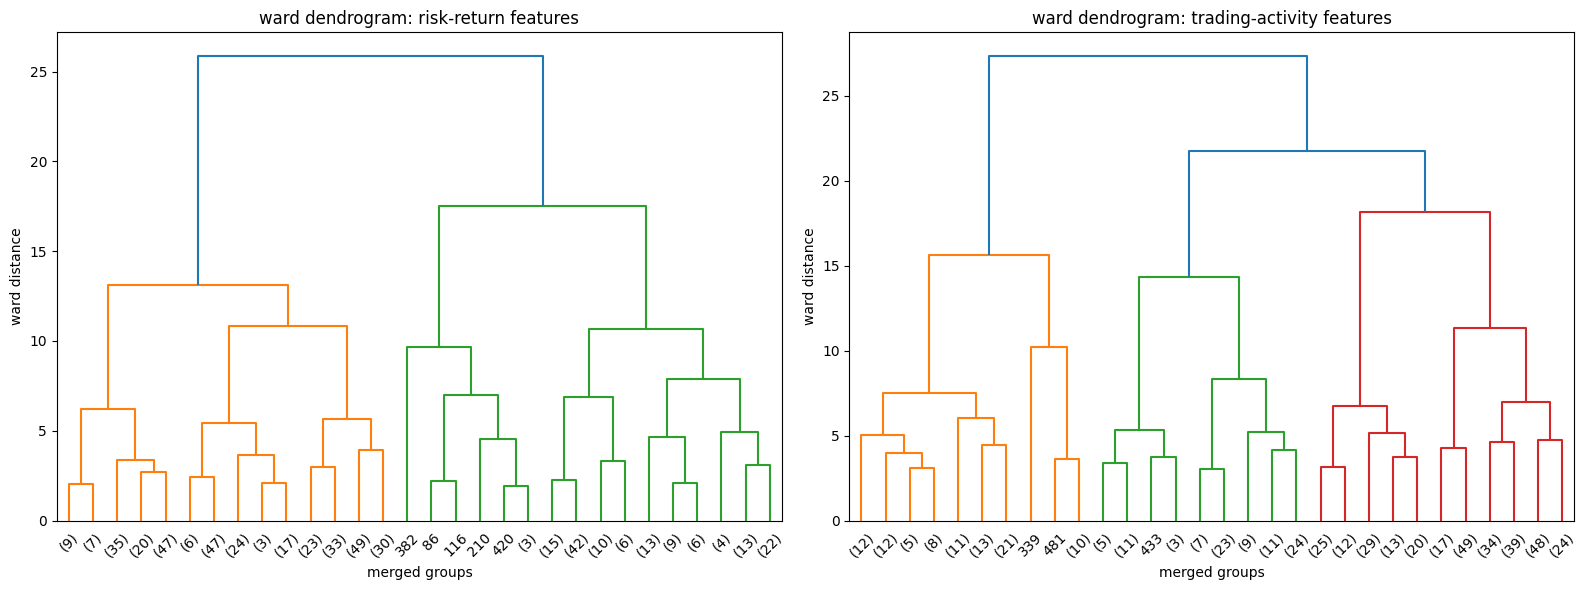

In [22]:
# part 17: create ward dendrograms for both feature matrices
risk_return_linkage = linkage(
    risk_return_scaled.values,
    method='ward',
    metric='euclidean'
)

trading_activity_linkage = linkage(
    trading_activity_scaled.values,
    method='ward',
    metric='euclidean'
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

dendrogram(
    risk_return_linkage,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True,
    ax=axes[0]
)
axes[0].set_title('ward dendrogram: risk-return features')
axes[0].set_xlabel('merged groups')
axes[0].set_ylabel('ward distance')

dendrogram(
    trading_activity_linkage,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True,
    ax=axes[1]
)
axes[1].set_title('ward dendrogram: trading-activity features')
axes[1].set_xlabel('merged groups')
axes[1].set_ylabel('ward distance')

plt.tight_layout()
plt.show()

In [23]:
# part 18: compare ward cluster counts from two to eight
agglomerative_results = []
agglomerative_labels = {}

feature_sets = {
    'risk_return': risk_return_scaled,
    'trading_activity': trading_activity_scaled
}

for feature_set_name, matrix in feature_sets.items():
    agglomerative_labels[feature_set_name] = {}

    for cluster_count in range(2, 9):
        model = AgglomerativeClustering(
            n_clusters=cluster_count,
            linkage='ward',
            metric='euclidean'
        )

        labels = model.fit_predict(matrix)
        agglomerative_labels[feature_set_name][cluster_count] = labels

        cluster_sizes = pd.Series(labels).value_counts().sort_index()

        agglomerative_results.append({
            'Feature_Set': feature_set_name,
            'Clusters': cluster_count,
            'Silhouette': silhouette_score(matrix, labels, metric='euclidean'),
            'Cluster_Sizes': cluster_sizes.to_dict()
        })

agglomerative_results = pd.DataFrame(agglomerative_results)
agglomerative_results

,Feature_Set,Clusters,Silhouette,Cluster_Sizes
0,risk_return,2,0.399833,"{0: 148, 1: 350}"
1,risk_return,3,0.382498,"{0: 350, 1: 140, 2: 8}"
2,risk_return,4,0.250147,"{0: 232, 1: 140, 2: 8, 3: 118}"
3,risk_return,5,0.259250,"{0: 140, 1: 118, 2: 8, 3: 135, 4: 97}"
4,risk_return,6,0.281736,"{0: 8, 1: 118, 2: 67, 3: 135, 4: 97, 5: 73}"
5,risk_return,7,0.283119,"{0: 67, 1: 118, 2: 7, 3: 135, 4: 97, 5: 73, 6: 1}"
6,risk_return,8,0.292828,"{0: 7, 1: 118, 2: 73, 3: 135, 4: 97, 5: 39, 6:..."
7,trading_activity,2,0.358679,"{0: 404, 1: 94}"
8,trading_activity,3,0.316000,"{0: 310, 1: 94, 2: 94}"
9,trading_activity,4,0.287608,"{0: 94, 1: 211, 2: 94, 3: 99}"


In [24]:
# part 19: compare agglomerative cluster profiles in original units
original_feature_sets = {
    'risk_return': common_feature_table[
        ['Mean_Weekly_Return', 'Weekly_Beta']
    ],
    'trading_activity': common_feature_table[
        ['Recency_Days', 'Frequency', 'Monetary_USD']
    ]
}

agglomerative_profile_tables = {}

for feature_set_name, original_features in original_feature_sets.items():
    profile_rows = []

    for cluster_count in range(2, 9):
        labels = agglomerative_labels[feature_set_name][cluster_count]

        clustered_features = original_features.copy()
        clustered_features['Cluster'] = labels

        profile = clustered_features.groupby('Cluster')[original_features.columns].agg(
            ['mean', 'median']
        )
        profile.columns = [
            f'{feature}_{statistic}'
            for feature, statistic in profile.columns
        ]
        profile.insert(
            0,
            'Cluster_Size',
            clustered_features.groupby('Cluster').size()
        )
        profile.insert(0, 'Clusters', cluster_count)
        profile.insert(0, 'Feature_Set', feature_set_name)
        profile_rows.append(profile.reset_index())

    agglomerative_profile_tables[feature_set_name] = pd.concat(
        profile_rows,
        ignore_index=True
    )

print('Risk-return profiles')
display(agglomerative_profile_tables['risk_return'])

print('Trading-activity profiles')
display(agglomerative_profile_tables['trading_activity'])

Risk-return profiles


,Cluster,Feature_Set,Clusters,Cluster_Size,Mean_Weekly_Return_mean,Mean_Weekly_Return_median,Weekly_Beta_mean,Weekly_Beta_median
0,0,risk_return,2,148,0.005356,0.004694,1.432387,1.359566
1,1,risk_return,2,350,0.002064,0.002086,0.795007,0.831814
2,0,risk_return,3,350,0.002064,0.002086,0.795007,0.831814
3,1,risk_return,3,140,0.004666,0.004595,1.378855,1.349887
4,2,risk_return,3,8,0.017432,0.014009,2.369210,2.280412
5,0,risk_return,4,232,0.002513,0.002549,0.655630,0.653625
6,1,risk_return,4,140,0.004666,0.004595,1.378855,1.349887
7,2,risk_return,4,8,0.017432,0.014009,2.369210,2.280412
8,3,risk_return,4,118,0.001183,0.001525,1.069036,1.057506
9,0,risk_return,5,140,0.004666,0.004595,1.378855,1.349887


Trading-activity profiles


,Cluster,Feature_Set,Clusters,Cluster_Size,Recency_Days_mean,Recency_Days_median,Frequency_mean,Frequency_median,Monetary_USD_mean,Monetary_USD_median
0,0,trading_activity,2,404,12.361386,11.0,3.220297,3.0,3.820898e+10,1.547309e+10
1,1,trading_activity,2,94,55.531915,53.0,2.074468,2.0,4.565006e+10,2.095020e+10
2,0,trading_activity,3,310,11.370968,11.0,2.729032,3.0,2.238726e+10,1.429831e+10
3,1,trading_activity,3,94,55.531915,53.0,2.074468,2.0,4.565006e+10,2.095020e+10
4,2,trading_activity,3,94,15.627660,11.0,4.840426,5.0,9.038697e+10,2.663978e+10
5,0,trading_activity,4,94,55.531915,53.0,2.074468,2.0,4.565006e+10,2.095020e+10
6,1,trading_activity,4,211,11.137441,11.0,2.947867,3.0,1.109817e+10,1.078591e+10
7,2,trading_activity,4,94,15.627660,11.0,4.840426,5.0,9.038697e+10,2.663978e+10
8,3,trading_activity,4,99,11.868687,11.0,2.262626,2.0,4.644786e+10,3.606800e+10
9,0,trading_activity,5,94,15.627660,11.0,4.840426,5.0,9.038697e+10,2.663978e+10


In [25]:
# import required library
from sklearn.cluster import KMeans

In [26]:
# part 20: compare k-means cluster counts from two to eight
kmeans_results = []
kmeans_labels = {}

for feature_set_name, matrix in feature_sets.items():
    kmeans_labels[feature_set_name] = {}

    for cluster_count in range(2, 9):
# apply the same seeded setup for each candidate k
        model = KMeans(
            n_clusters=cluster_count,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(matrix)
        kmeans_labels[feature_set_name][cluster_count] = labels

        cluster_sizes = pd.Series(labels).value_counts().sort_index()

        kmeans_results.append({
            'Feature_Set': feature_set_name,
            'Clusters': cluster_count,
            'Silhouette': silhouette_score(matrix, labels, metric='euclidean'),
            'Inertia': model.inertia_,
            'Cluster_Sizes': cluster_sizes.to_dict()
        })

kmeans_results = pd.DataFrame(kmeans_results)
kmeans_results

,Feature_Set,Clusters,Silhouette,Inertia,Cluster_Sizes
0,risk_return,2,0.399850,658.382887,"{0: 350, 1: 148}"
1,risk_return,3,0.350123,497.903020,"{0: 207, 1: 282, 2: 9}"
2,risk_return,4,0.337679,386.219639,"{0: 176, 1: 122, 2: 8, 3: 192}"
3,risk_return,5,0.348440,318.226596,"{0: 142, 1: 57, 2: 7, 3: 188, 4: 104}"
4,risk_return,6,0.352586,264.790001,"{0: 186, 1: 104, 2: 142, 3: 57, 4: 2, 5: 7}"
5,risk_return,7,0.337676,225.076596,"{0: 153, 1: 7, 2: 108, 3: 54, 4: 80, 5: 94, 6: 2}"
6,risk_return,8,0.327556,194.993452,"{0: 88, 1: 103, 2: 127, 3: 7, 4: 2, 5: 52, 6: ..."
7,trading_activity,2,0.418999,1094.049704,"{0: 72, 1: 426}"
8,trading_activity,3,0.324209,818.263499,"{0: 277, 1: 157, 2: 64}"
9,trading_activity,4,0.340464,625.212105,"{0: 61, 1: 216, 2: 97, 3: 124}"


In [27]:
# part 18 and part 20: display full cluster size counts

print('ward cluster sizes')
for row in agglomerative_results.itertuples(index=False):
    print(f'{row.Feature_Set}, k={row.Clusters}: {row.Cluster_Sizes}')

print('\nk-means cluster sizes')
for row in kmeans_results.itertuples(index=False):
    print(f'{row.Feature_Set}, k={row.Clusters}: {row.Cluster_Sizes}')

ward cluster sizes
risk_return, k=2: {0: 148, 1: 350}
risk_return, k=3: {0: 350, 1: 140, 2: 8}
risk_return, k=4: {0: 232, 1: 140, 2: 8, 3: 118}
risk_return, k=5: {0: 140, 1: 118, 2: 8, 3: 135, 4: 97}
risk_return, k=6: {0: 8, 1: 118, 2: 67, 3: 135, 4: 97, 5: 73}
risk_return, k=7: {0: 67, 1: 118, 2: 7, 3: 135, 4: 97, 5: 73, 6: 1}
risk_return, k=8: {0: 7, 1: 118, 2: 73, 3: 135, 4: 97, 5: 39, 6: 1, 7: 28}
trading_activity, k=2: {0: 404, 1: 94}
trading_activity, k=3: {0: 310, 1: 94, 2: 94}
trading_activity, k=4: {0: 94, 1: 211, 2: 94, 3: 99}
trading_activity, k=5: {0: 94, 1: 211, 2: 12, 3: 99, 4: 82}
trading_activity, k=6: {0: 211, 1: 74, 2: 12, 3: 99, 4: 82, 5: 20}
trading_activity, k=7: {0: 12, 1: 74, 2: 145, 3: 99, 4: 82, 5: 20, 6: 66}
trading_activity, k=8: {0: 74, 1: 82, 2: 145, 3: 99, 4: 11, 5: 20, 6: 66, 7: 1}

k-means cluster sizes
risk_return, k=2: {0: 350, 1: 148}
risk_return, k=3: {0: 207, 1: 282, 2: 9}
risk_return, k=4: {0: 176, 1: 122, 2: 8, 3: 192}
risk_return, k=5: {0: 142, 1

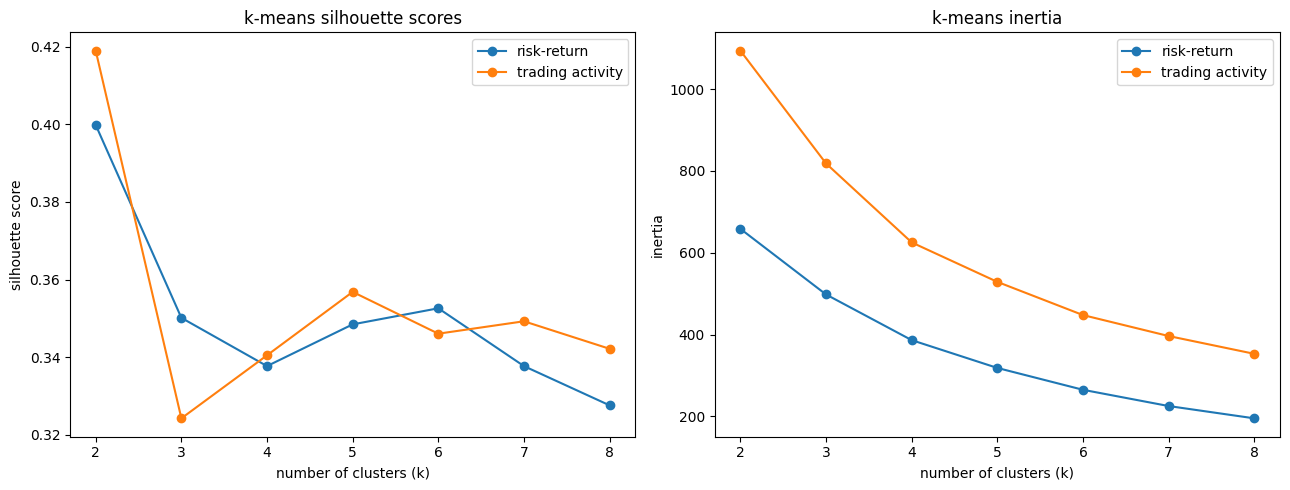

In [28]:
# part 20.1: plot k-means model selection diagnostics

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

feature_sets_to_plot = [
    ('risk_return', 'risk-return'),
    ('trading_activity', 'trading activity')
]

for feature_set_name, display_name in feature_sets_to_plot:
    results = kmeans_results[
        kmeans_results['Feature_Set'] == feature_set_name
    ].sort_values('Clusters')

    axes[0].plot(
        results['Clusters'],
        results['Silhouette'],
        marker='o',
        label=display_name
    )

    axes[1].plot(
        results['Clusters'],
        results['Inertia'],
        marker='o',
        label=display_name
    )

axes[0].set_title('k-means silhouette scores')
axes[0].set_xlabel('number of clusters (k)')
axes[0].set_ylabel('silhouette score')
axes[0].set_xticks(range(2, 9))
axes[0].legend()

axes[1].set_title('k-means inertia')
axes[1].set_xlabel('number of clusters (k)')
axes[1].set_ylabel('inertia')
axes[1].set_xticks(range(2, 9))
axes[1].legend()

plt.tight_layout()
fig.savefig('kmeans_model_selection.png', dpi=300, bbox_inches='tight')
plt.show()

In [29]:
# part 21: profile k-means two-cluster solutions in original units
kmeans_profile_tables = {}

for feature_set_name, original_features in original_feature_sets.items():
    labels = kmeans_labels[feature_set_name][2]

    clustered_features = original_features.copy()
    clustered_features['Cluster'] = labels

    profile = clustered_features.groupby('Cluster')[original_features.columns].agg(
        ['mean', 'median']
    )
    profile.columns = [
        f'{feature}_{statistic}'
        for feature, statistic in profile.columns
    ]
    profile.insert(
        0,
        'Cluster_Size',
        clustered_features.groupby('Cluster').size()
    )

    kmeans_profile_tables[feature_set_name] = profile.reset_index()

print('Risk-return K-Means profiles, k=2')
display(kmeans_profile_tables['risk_return'])

print('Trading-activity K-Means profiles, k=2')
display(kmeans_profile_tables['trading_activity'])

Risk-return K-Means profiles, k=2


,Cluster,Cluster_Size,Mean_Weekly_Return_mean,Mean_Weekly_Return_median,Weekly_Beta_mean,Weekly_Beta_median
0,0,350,0.002022,0.002046,0.797806,0.827582
1,1,148,0.005457,0.004816,1.425767,1.349887


Trading-activity K-Means profiles, k=2


,Cluster,Cluster_Size,Recency_Days_mean,Recency_Days_median,Frequency_mean,Frequency_median,Monetary_USD_mean,Monetary_USD_median
0,0,72,62.486111,55.0,1.847222,2.0,8.060058e+10,2.308445e+10
1,1,426,13.415493,11.0,3.199531,3.0,3.268613e+10,1.556962e+10


In [30]:
# part 22: audit weekly observation coverage
expected_market_weeks = int(weekly_returns['^GSPC'].notna().sum())
aligned_weeks = feature_table['Aligned_Weeks']

weekly_coverage_summary = pd.DataFrame({
    'Measure': [
        'Benchmark weekly returns available',
        'Shares with full benchmark coverage',
        'Shares with fewer than 52 aligned weeks',
        'Minimum aligned weeks for a share',
        'Median aligned weeks for a share',
        'Maximum aligned weeks for a share'
    ],
    'Value': [
        expected_market_weeks,
        int((aligned_weeks == expected_market_weeks).sum()),
        int((aligned_weeks < 52).sum()),
        int(aligned_weeks.min()),
        float(aligned_weeks.median()),
        int(aligned_weeks.max())
    ]
})

print('Weekly observation coverage')
display(weekly_coverage_summary)

print('Shares with the fewest aligned weekly observations')
display(
    feature_table[['Aligned_Weeks']]
    .sort_values('Aligned_Weeks')
    .head(10)
)

Weekly observation coverage


,Measure,Value
0,Benchmark weekly returns available,207.0
1,Shares with full benchmark coverage,486.0
2,Shares with fewer than 52 aligned weeks,4.0
3,Minimum aligned weeks for a share,24.0
4,Median aligned weeks for a share,207.0
5,Maximum aligned weeks for a share,207.0


Shares with the fewest aligned weekly observations


,Aligned_Weeks
Share,
SW,24
SOLV,39
GEV,39
RDDT,40
VLTO,64
GEHC,106
CEG,153
HOOD,178
APP,193


In [31]:
# part 23: inspect the small ward risk-return cluster
risk_k3_labels = pd.Series(
    agglomerative_labels['risk_return'][3],
    index=common_feature_table.index,
    name='Ward_Cluster_k3'
)

small_cluster_id = risk_k3_labels.value_counts().idxmin()
small_cluster_members = risk_k3_labels.index[
    risk_k3_labels == small_cluster_id
]

sector_by_ticker = (
    sp500_df.drop_duplicates('Yahoo Ticker')
    .set_index('Yahoo Ticker')['GICS Sector']
)

small_cluster_review = feature_table.loc[
    small_cluster_members,
    ['Mean_Weekly_Return', 'Weekly_Beta']
].join(sector_by_ticker.rename('GICS Sector'), how='left')

print('Small cluster id:', small_cluster_id)
print('Small cluster size:', len(small_cluster_members))
small_cluster_review.sort_values('Weekly_Beta', ascending=False)

Small cluster id: 2
Small cluster size: 8


,Mean_Weekly_Return,Weekly_Beta,GICS Sector
Share,,,
CVNA,0.010964,3.778560,Consumer Discretionary
COIN,0.006697,3.004326,Financials
RDDT,0.038491,2.486226,Communication Services
APP,0.014393,2.434869,Communication Services
NVDA,0.013624,2.125954,Information Technology
VRT,0.012583,2.001479,Industrials
SMCI,0.017772,1.783662,Information Technology
GEV,0.024936,1.338605,Industrials


In [32]:
# import all required libraries
from sklearn.metrics import adjusted_rand_score
from sklearn.decomposition import PCA

In [33]:
# part 24: compare ward and k-means cluster memberships
selected_counts = {
    'risk_return': {'ward': 2, 'kmeans': 2},
    'trading_activity': {'ward': 2, 'kmeans': 2}
}

algorithm_comparison_rows = []

for feature_set_name, cluster_counts in selected_counts.items():
    ward_count = cluster_counts['ward']
    kmeans_count = cluster_counts['kmeans']

    ward_labels = agglomerative_labels[feature_set_name][ward_count]
    kmeans_cluster_labels = kmeans_labels[feature_set_name][kmeans_count]

# record agreement between matched clusterings
    algorithm_comparison_rows.append({
        'Feature_Set': feature_set_name,
        'Shares_Compared': len(common_feature_table),
        'Ward_Clusters': ward_count,
        'Ward_Cluster_Sizes': pd.Series(ward_labels).value_counts().sort_index().to_dict(),
        'KMeans_Clusters': kmeans_count,
        'KMeans_Cluster_Sizes': (
            pd.Series(kmeans_cluster_labels).value_counts().sort_index().to_dict()
        ),
        'Adjusted_Rand_Index': adjusted_rand_score(ward_labels, kmeans_cluster_labels)
    })

algorithm_comparison = pd.DataFrame(algorithm_comparison_rows)
algorithm_comparison

,Feature_Set,Shares_Compared,Ward_Clusters,Ward_Cluster_Sizes,KMeans_Clusters,KMeans_Cluster_Sizes,Adjusted_Rand_Index
0,risk_return,498,2,"{0: 148, 1: 350}",2,"{0: 350, 1: 148}",0.934922
1,trading_activity,498,2,"{0: 404, 1: 94}",2,"{0: 72, 1: 426}",0.753690


Variance explained by trading-activity PC1 and PC2: 0.796


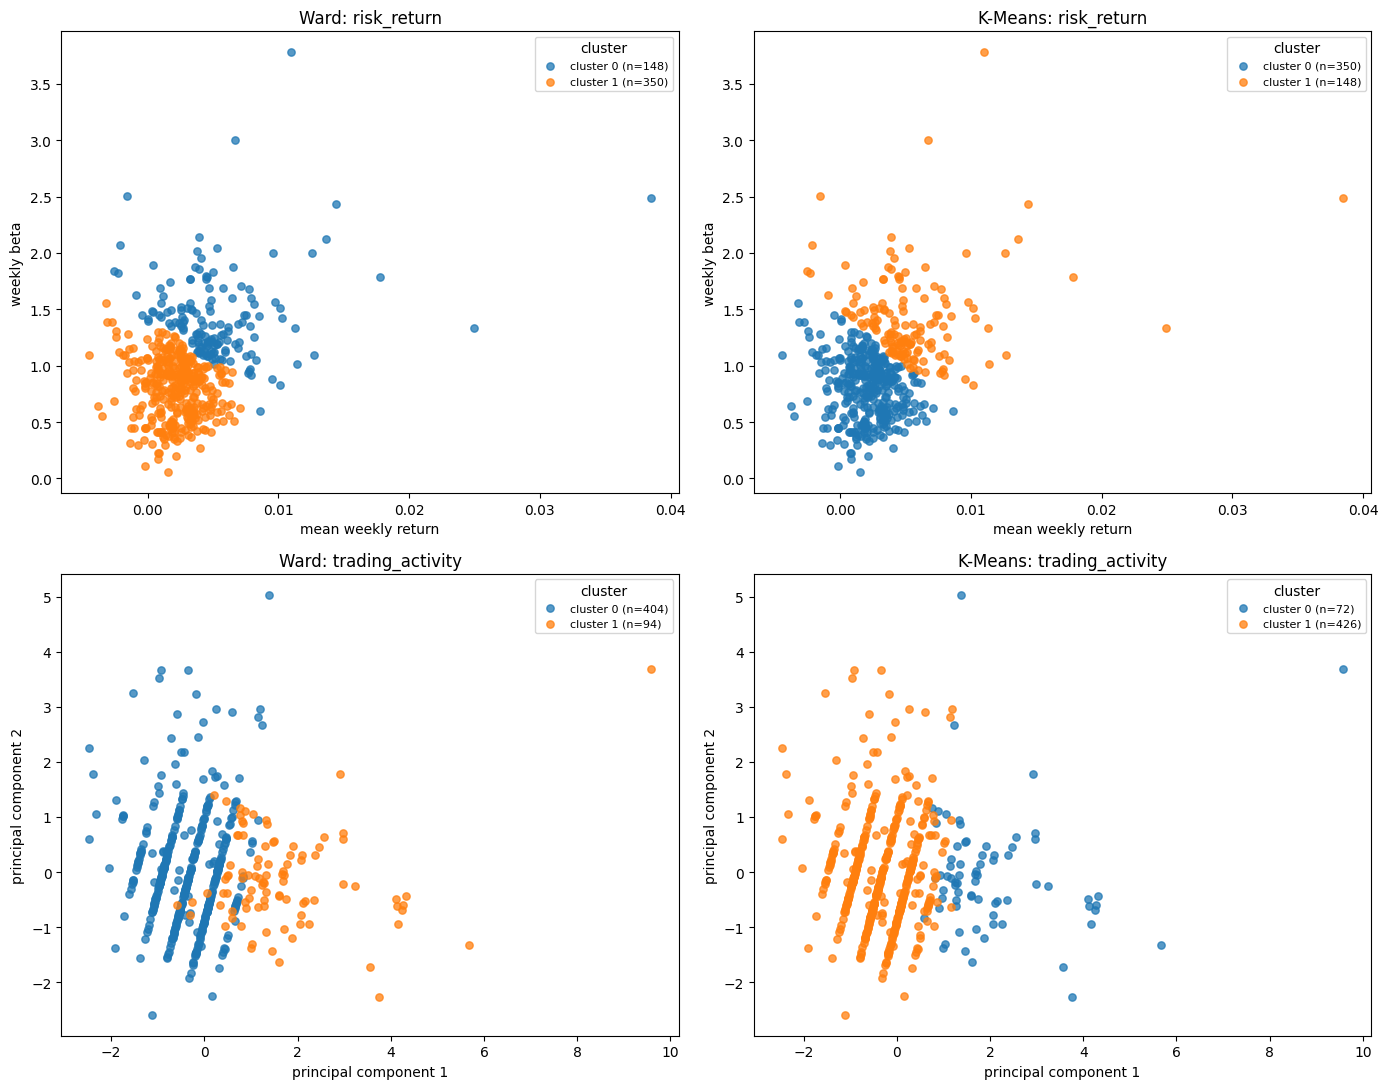

In [34]:
# part 25: plot the selected cluster solutions in two dimensions
# prepare a two-dimensional view of the activity features
trading_activity_pca = PCA(n_components=2)
trading_activity_coordinates = trading_activity_pca.fit_transform(
    trading_activity_scaled
)

trading_activity_plot = pd.DataFrame(
    trading_activity_coordinates,
    index=trading_activity_scaled.index,
    columns=['PC1', 'PC2']
)

print(
    'Variance explained by trading-activity PC1 and PC2:',
    round(trading_activity_pca.explained_variance_ratio_.sum(), 3)
)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

plot_specs = [
    (
        axes[0, 0], 'risk_return', 'Ward',
        agglomerative_labels['risk_return'][selected_counts['risk_return']['ward']]
    ),
    (
        axes[0, 1], 'risk_return', 'K-Means',
        kmeans_labels['risk_return'][selected_counts['risk_return']['kmeans']]
    ),
    (
        axes[1, 0], 'trading_activity', 'Ward',
        agglomerative_labels['trading_activity'][
            selected_counts['trading_activity']['ward']
        ]
    ),
    (
        axes[1, 1], 'trading_activity', 'K-Means',
        kmeans_labels['trading_activity'][
            selected_counts['trading_activity']['kmeans']
        ]
    )
]

for axis, feature_set_name, algorithm_name, labels in plot_specs:
    if feature_set_name == 'risk_return':
        x_values = common_feature_table['Mean_Weekly_Return']
        y_values = common_feature_table['Weekly_Beta']
        axis.set_xlabel('mean weekly return')
        axis.set_ylabel('weekly beta')
    else:
        x_values = trading_activity_plot['PC1']
        y_values = trading_activity_plot['PC2']
        axis.set_xlabel('principal component 1')
        axis.set_ylabel('principal component 2')

    for cluster_id in sorted(set(labels)):
        cluster_mask = labels == cluster_id
        cluster_size = int(cluster_mask.sum())

        axis.scatter(
            x_values.iloc[cluster_mask],
            y_values.iloc[cluster_mask],
            label=f'cluster {cluster_id} (n={cluster_size})',
            s=28,
            alpha=0.75
        )

    axis.set_title(f'{algorithm_name}: {feature_set_name}')
    axis.legend(title='cluster', fontsize=8)

plt.tight_layout()
plt.show()

In [35]:
# part 26: inspect trading-activity pca components
pca_loadings = pd.DataFrame(
    trading_activity_pca.components_.T,
    index=trading_activity_scaled.columns,
    columns=['PC1_Weight', 'PC2_Weight']
)

pca_variance = pd.Series(
    trading_activity_pca.explained_variance_ratio_,
    index=['PC1', 'PC2'],
    name='Variance_Explained'
)

print('Variance explained by each component')
display(pca_variance)

print('Feature weights for each component')
pca_loadings

Variance explained by each component


,Variance_Explained
PC1,0.456589
PC2,0.339043


Feature weights for each component


,PC1_Weight,PC2_Weight
Recency_Days,0.714581,0.036018
Frequency,-0.640930,0.433901
Log_Monetary,0.280327,0.900241


Pearson correlation matrix


,Recency_Days,Frequency,Log_Monetary
Recency_Days,1.000,-0.340,0.165
Frequency,-0.340,1.000,0.022
Log_Monetary,0.165,0.022,1.000


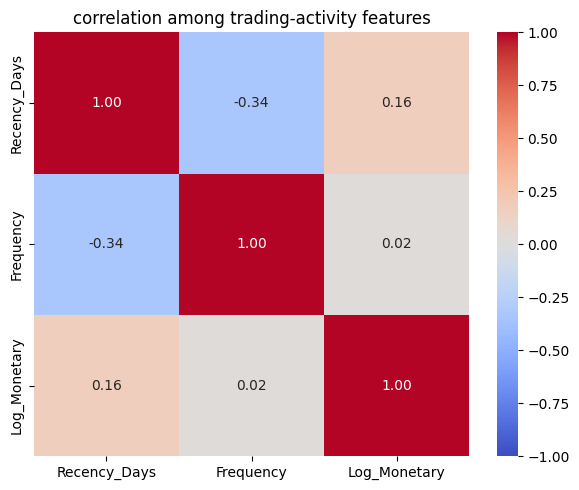

In [36]:
# part 27: calculate and visualise rfm feature correlations
rfm_correlation = trading_activity_matrix[
    ['Recency_Days', 'Frequency', 'Log_Monetary']
].corr(method='pearson')

print('Pearson correlation matrix')
display(rfm_correlation.round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(
    rfm_correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)
plt.title('correlation among trading-activity features')
plt.tight_layout()
plt.show()

In [37]:
# part 28: test ward rfm sensitivity without monetary
rf_only_matrix = common_feature_table[
    ['Recency_Days', 'Frequency']
].copy()

rf_only_scaler = StandardScaler()
rf_only_scaled = pd.DataFrame(
    rf_only_scaler.fit_transform(rf_only_matrix),
    index=rf_only_matrix.index,
    columns=rf_only_matrix.columns
)

ward_rf_model = AgglomerativeClustering(
    n_clusters=selected_counts['trading_activity']['ward'],
    linkage='ward',
    metric='euclidean'
)
rf_only_labels = ward_rf_model.fit_predict(rf_only_scaled)

ward_rfm_baseline_labels = agglomerative_labels['trading_activity'][
    selected_counts['trading_activity']['ward']
]

# compare reduced and baseline cluster assignments
rf_only_ari = adjusted_rand_score(
    ward_rfm_baseline_labels,
    rf_only_labels
)

print('ARI: Ward RFM baseline versus Ward using Recency and Frequency only')
print(round(rf_only_ari, 3))

def monetary_cluster_profile(labels, solution_name):
    profile_data = pd.DataFrame(
        {
            'Cluster': labels,
            'Monetary_USD': common_feature_table['Monetary_USD'].values
        },
        index=common_feature_table.index
    )

    profile = profile_data.groupby('Cluster').agg(
        Cluster_Size=('Monetary_USD', 'size'),
        Mean_Traded_Value_USD=('Monetary_USD', 'mean'),
        Median_Traded_Value_USD=('Monetary_USD', 'median')
    )
    profile.insert(0, 'Solution', solution_name)
    return profile.reset_index()

baseline_monetary_profile = monetary_cluster_profile(
    ward_rfm_baseline_labels,
    'ward rfm baseline'
)

rf_only_monetary_profile = monetary_cluster_profile(
    rf_only_labels,
    'ward recency and frequency only'
)

monetary_profile_comparison = pd.concat(
    [baseline_monetary_profile, rf_only_monetary_profile],
    ignore_index=True
)

monetary_profile_comparison

ARI: Ward RFM baseline versus Ward using Recency and Frequency only
0.953


,Cluster,Solution,Cluster_Size,Mean_Traded_Value_USD,Median_Traded_Value_USD
0,0,ward rfm baseline,404,3.820898e+10,1.547309e+10
1,1,ward rfm baseline,94,4.565006e+10,2.095020e+10
2,0,ward recency and frequency only,405,3.768854e+10,1.545679e+10
3,1,ward recency and frequency only,93,4.799647e+10,2.105259e+10


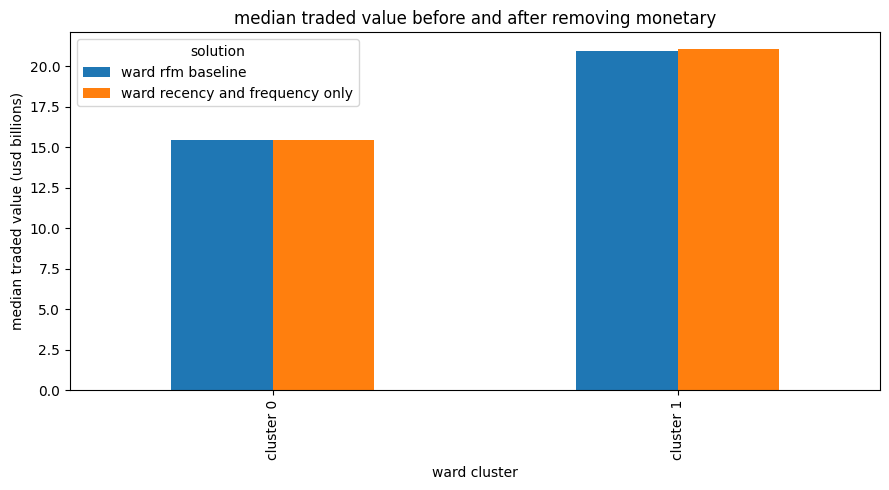

In [38]:
# part 28.1: plot median traded value before and after removing monetary

comparison_plot = monetary_profile_comparison.pivot(
    index='Cluster',
    columns='Solution',
    values='Median_Traded_Value_USD'
) / 1e9

comparison_plot = comparison_plot.rename(
    index={0: 'cluster 0', 1: 'cluster 1'}
)

comparison_plot = comparison_plot[
    ['ward rfm baseline', 'ward recency and frequency only']
]

fig, ax = plt.subplots(figsize=(9, 5))
comparison_plot.plot(kind='bar', ax=ax)

ax.set_title('median traded value before and after removing monetary')
ax.set_xlabel('ward cluster')
ax.set_ylabel('median traded value (usd billions)')
ax.legend(title='solution')
plt.tight_layout()

fig.savefig(
    'ward_monetary_sensitivity.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [39]:
# part 29: data-quality test
price_fields = ['Close', 'Adj Close']
quality_rows = []

print('Duplicate dates:', int(daily_data.index.duplicated().sum()))

for field in price_fields:
    field_data = daily_data[field][included_tickers]
    quality_rows.append({
        'Check': f'{field} missing values',
        'Count': int(field_data.isna().sum().sum())
    })
    quality_rows.append({
        'Check': f'{field} nonpositive values',
        'Count': int((field_data <= 0).sum().sum())
    })

volume_data = daily_data['Volume'][included_tickers]
quality_rows.append({
    'Check': 'Volume missing values',
    'Count': int(volume_data.isna().sum().sum())
})
quality_rows.append({
    'Check': 'Volume zero values',
    'Count': int((volume_data == 0).sum().sum())
})
quality_rows.append({
    'Check': 'Volume negative values',
    'Count': int((volume_data < 0).sum().sum())
})

for field in ['Dividends', 'Stock Splits']:
    if field in daily_data.columns.get_level_values(0):
        action_data = daily_data[field][included_tickers]
        quality_rows.append({
            'Check': f'Nonzero {field} entries',
            'Count': int((action_data.fillna(0) != 0).sum().sum())
        })

quality_summary = pd.DataFrame(quality_rows)
quality_summary

Duplicate dates: 0


,Check,Count
0,Close missing values,5110
1,Close nonpositive values,0
2,Adj Close missing values,5110
3,Adj Close nonpositive values,0
4,Volume missing values,5110
5,Volume zero values,0
6,Volume negative values,0
7,Nonzero Dividends entries,6079
8,Nonzero Stock Splits entries,61


In [40]:
# part 30: inspect missing histories and zero-volume entries
close_data = daily_data['Close'][included_tickers]
adjusted_data = daily_data['Adj Close'][included_tickers]
volume_data = daily_data['Volume'][included_tickers]

missing_by_ticker = pd.DataFrame({
    'Close_Missing': close_data.isna().sum(),
    'Adj_Close_Missing': adjusted_data.isna().sum(),
    'Volume_Missing': volume_data.isna().sum()
}).sort_values('Close_Missing', ascending=False)

print('Shares with the most missing history')
display(missing_by_ticker.head(15))

zero_volume_mask = volume_data == 0
zero_volume_counts = zero_volume_mask.sum()
zero_volume_tickers = zero_volume_counts[zero_volume_counts > 0].sort_values(
    ascending=False
)

# separate zero-volume records by price availability
zero_with_close = zero_volume_mask & close_data.notna()
zero_without_close = zero_volume_mask & close_data.isna()

zero_volume_summary = pd.DataFrame({
    'Zero_Volume_Days': zero_volume_tickers,
    'Zero_Volume_Days_With_Close': zero_with_close.sum().reindex(
        zero_volume_tickers.index
    ),
    'First_Zero_Volume_Date': {
        share: volume_data.index[zero_volume_mask[share]].min()
        for share in zero_volume_tickers.index
    },
    'Last_Zero_Volume_Date': {
        share: volume_data.index[zero_volume_mask[share]].max()
        for share in zero_volume_tickers.index
    }
})

print('Zero-volume entries with a recorded Close:', int(zero_with_close.sum().sum()))
print('Zero-volume entries without a recorded Close:', int(zero_without_close.sum().sum()))
print('Shares with the most zero-volume entries')
display(zero_volume_summary.head(15))

Shares with the most missing history


,Close_Missing,Adj_Close_Missing,Volume_Missing
Ticker,,,
SW,881,881,881
GEV,812,812,812
SOLV,811,811,811
RDDT,808,808,808
VLTO,692,692,692
GEHC,492,492,492
CEG,263,263,263
HOOD,143,143,143
APP,70,70,70


Zero-volume entries with a recorded Close: 0
Zero-volume entries without a recorded Close: 0
Shares with the most zero-volume entries


,Zero_Volume_Days,Zero_Volume_Days_With_Close,First_Zero_Volume_Date,Last_Zero_Volume_Date


Task 3: Business Intelligence and Critical Review

Shares without a sector classification: 0


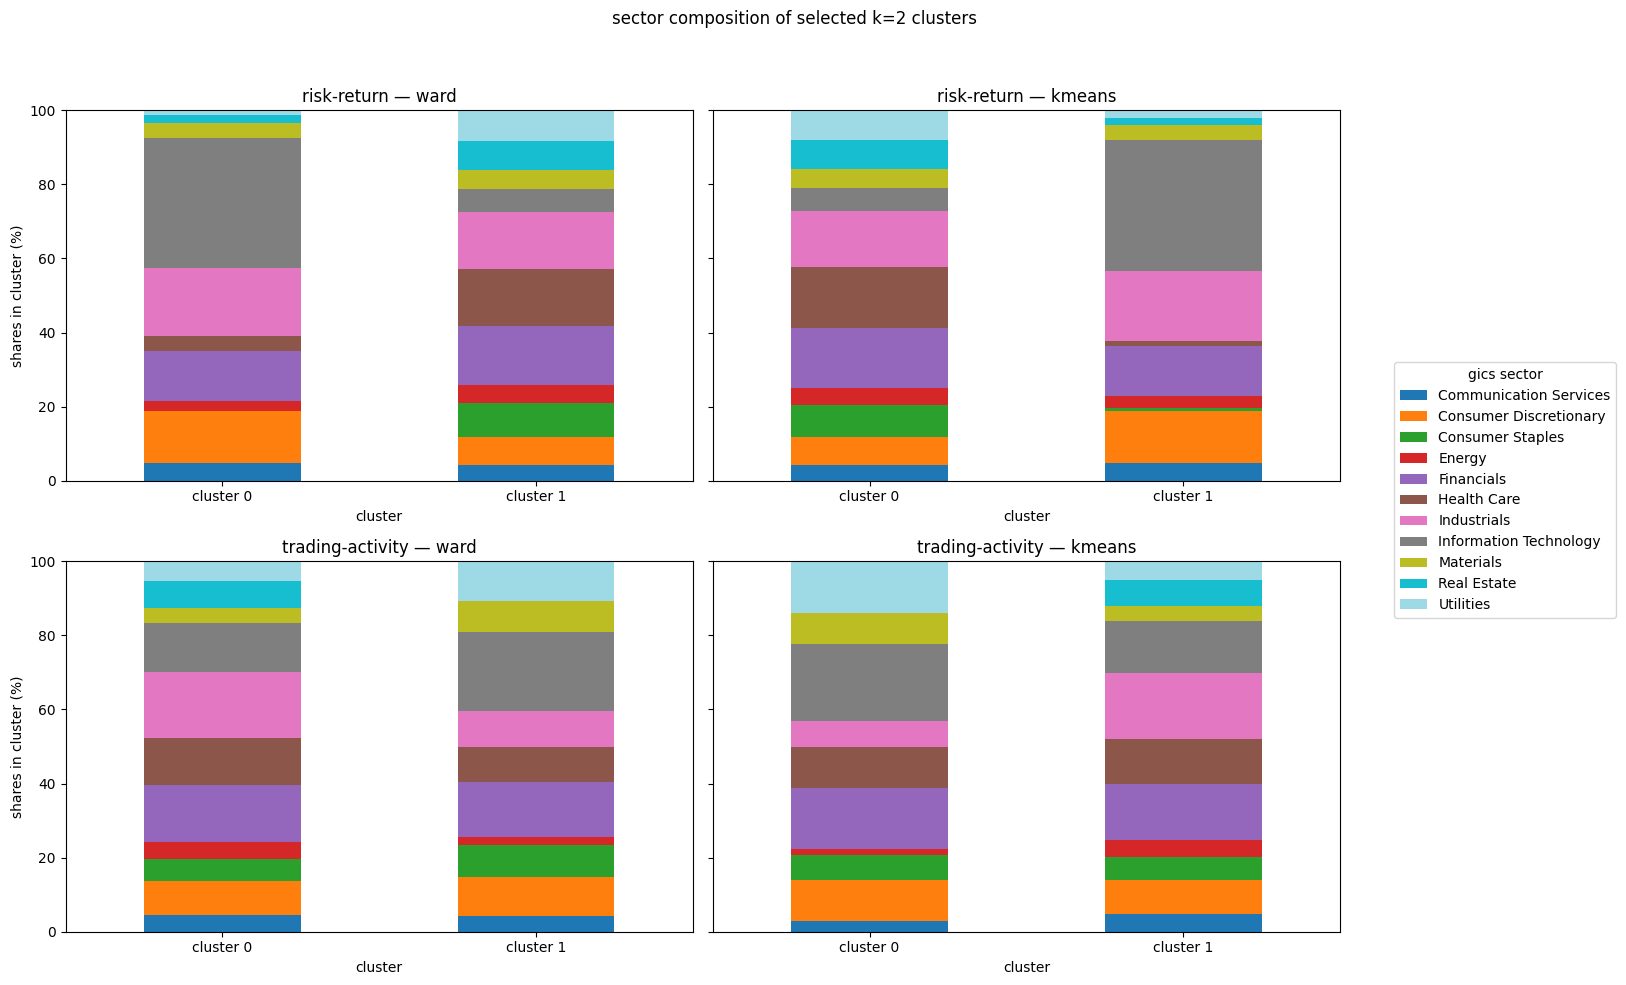

,Feature_Set,Algorithm,Cluster,GICS_Sector,Share_Count,Cluster_Percent
26,risk_return,kmeans,0,Health Care,58,16.6
25,risk_return,kmeans,0,Financials,56,16.0
27,risk_return,kmeans,0,Industrials,53,15.1
23,risk_return,kmeans,0,Consumer Staples,31,8.9
31,risk_return,kmeans,0,Utilities,28,8.0
...,...,...,...,...,...,...
60,trading_activity,ward,1,Industrials,9,9.6
56,trading_activity,ward,1,Consumer Staples,8,8.5
62,trading_activity,ward,1,Materials,8,8.5
54,trading_activity,ward,1,Communication Services,4,4.3


In [41]:
# task 3.2.1: compare sector composition in selected k=2 clusters

sector_lookup = (
    sp500_df.drop_duplicates('Yahoo Ticker')
    .set_index('Yahoo Ticker')['GICS Sector']
    .reindex(common_feature_table.index)
)

print('Shares without a sector classification:', int(sector_lookup.isna().sum()))

solutions = [
    ('risk_return', 'ward', agglomerative_labels['risk_return'][2]),
    ('risk_return', 'kmeans', kmeans_labels['risk_return'][2]),
    ('trading_activity', 'ward', agglomerative_labels['trading_activity'][2]),
    ('trading_activity', 'kmeans', kmeans_labels['trading_activity'][2])
]

all_sectors = sorted(sector_lookup.dropna().unique())
sector_rows = []

fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
axes = axes.flatten()

for axis, (feature_set, algorithm, labels) in zip(axes, solutions):
    cluster_labels = pd.Series(labels, index=common_feature_table.index)

    cluster_sector = pd.DataFrame({
        'Cluster': cluster_labels,
        'GICS Sector': sector_lookup
    })

    sector_counts = pd.crosstab(
        cluster_sector['Cluster'],
        cluster_sector['GICS Sector']
    ).reindex(columns=all_sectors, fill_value=0)

    sector_percentages = (
        sector_counts.div(sector_counts.sum(axis=1), axis=0) * 100
    ).fillna(0)

    for cluster in sector_counts.index:
        for sector in all_sectors:
            count = int(sector_counts.loc[cluster, sector])

            if count > 0:
                sector_rows.append({
                    'Feature_Set': feature_set,
                    'Algorithm': algorithm,
                    'Cluster': cluster,
                    'GICS_Sector': sector,
                    'Share_Count': count,
                    'Cluster_Percent': round(
                        sector_percentages.loc[cluster, sector], 1
                    )
                })

    sector_percentages.plot(
        kind='bar',
        stacked=True,
        colormap='tab20',
        legend=False,
        ax=axis
    )

    legend_handles, legend_labels = axis.get_legend_handles_labels()
    axis.set_title(f'{feature_set.replace("_", "-")} — {algorithm}')
    axis.set_xlabel('cluster')
    axis.set_ylabel('shares in cluster (%)')
    axis.set_ylim(0, 100)
    axis.set_xticklabels(
        [f'cluster {cluster}' for cluster in sector_counts.index],
        rotation=0
    )

fig.legend(
    legend_handles,
    legend_labels,
    title='gics sector',
    loc='center left',
    bbox_to_anchor=(0.87, 0.5)
)
fig.suptitle('sector composition of selected k=2 clusters')
fig.tight_layout(rect=[0, 0, 0.85, 0.95])
plt.show()

sector_composition = pd.DataFrame(sector_rows).sort_values(
    ['Feature_Set', 'Algorithm', 'Cluster', 'Cluster_Percent'],
    ascending=[True, True, True, False]
)

display(sector_composition)

In [42]:
# display the 3 largest sector shares within each cluster

top_sector_mix = (
    sector_composition
    .sort_values(
        ['Feature_Set', 'Algorithm', 'Cluster', 'Cluster_Percent'],
        ascending=[True, True, True, False]
    )
    .groupby(
        ['Feature_Set', 'Algorithm', 'Cluster'],
        as_index=False
    )
    .head(3)
    .reset_index(drop=True)
)

display(top_sector_mix)

,Feature_Set,Algorithm,Cluster,GICS_Sector,Share_Count,Cluster_Percent
0,risk_return,kmeans,0,Health Care,58,16.6
1,risk_return,kmeans,0,Financials,56,16.0
2,risk_return,kmeans,0,Industrials,53,15.1
3,risk_return,kmeans,1,Information Technology,52,35.1
4,risk_return,kmeans,1,Industrials,28,18.9
5,risk_return,kmeans,1,Consumer Discretionary,21,14.2
6,risk_return,ward,0,Information Technology,52,35.1
7,risk_return,ward,0,Industrials,27,18.2
8,risk_return,ward,0,Consumer Discretionary,21,14.2
9,risk_return,ward,1,Financials,56,16.0


In [43]:
# import required library
from zipfile import ZIP_DEFLATED, ZipFile

# prepare sector labels for the exported cluster assignments
ticker_sectors = (
    sp500_df.drop_duplicates('Yahoo Ticker')
    .set_index('Yahoo Ticker')['GICS Sector']
)

baseline_label_sets = [
    ('risk_return', 'ward', agglomerative_labels['risk_return'][2]),
    ('risk_return', 'kmeans', kmeans_labels['risk_return'][2]),
    ('trading_activity', 'ward', agglomerative_labels['trading_activity'][2]),
    ('trading_activity', 'kmeans', kmeans_labels['trading_activity'][2])
]

cluster_assignment_parts = []

for feature_set_name, algorithm_name, labels in baseline_label_sets:
    cluster_assignment_parts.append(pd.DataFrame({
        'Ticker': common_feature_table.index,
        'GICS_Sector': common_feature_table.index.map(ticker_sectors),
        'Feature_Set': feature_set_name,
        'Algorithm': algorithm_name,
        'Cluster_Count': 2,
        'Cluster': labels
    }))

sensitivity_assignments = pd.DataFrame({
    'Ticker': common_feature_table.index,
    'GICS_Sector': common_feature_table.index.map(ticker_sectors),
    'Feature_Set': 'trading_activity_rf_only',
    'Algorithm': 'ward',
    'Cluster_Count': selected_counts['trading_activity']['ward'],
    'Cluster': rf_only_labels
})

cluster_assignments = pd.concat(
    cluster_assignment_parts + [sensitivity_assignments],
    ignore_index=True
)

run_metadata = pd.DataFrame([{
    'Data_Sources': 'Wikipedia and Yahoo Finance',
    'Ticker_List_Retrieval_Date': str(sp500_df['Retrieval Date'].iloc[0]),
    'Start_Date_Inclusive': start,
    'End_Date_Exclusive': end,
    'Observation_Date': str(pd.Timestamp(observation_date).date()),
    'Benchmark': '^GSPC',
    'Included_Shares': len(included_tickers),
    'Excluded_Shares': len(excluded_tickers)
}])

snapshot_tables = {
    'sp500_tickers.csv': (sp500_df, False),
    'raw_download_snapshot.csv': (downloaded_daily_data, True),
    'analysis_market_data.csv': (daily_data, True),
    'weekly_returns.csv': (weekly_returns, True),
    'feature_table.csv': (feature_table, True),
    'common_feature_table.csv': (common_feature_table, True),
    'cluster_assignments.csv': (cluster_assignments, False),
    'algorithm_comparison.csv': (algorithm_comparison, False),
    'monetary_profile_comparison.csv': (monetary_profile_comparison, False),
    'sector_composition.csv': (sector_composition, False),
    'exclusion_log.csv': (exclusion_log, False),
    'validation_summary.csv': (validation_summary, False),
    'package_versions.csv': (package_versions, False),
    'run_metadata.csv': (run_metadata, False)
}

for file_name, (table, include_index) in snapshot_tables.items():
    table.to_csv(file_name, index=include_index)

with ZipFile('cw1_data_snapshots.zip', 'w', ZIP_DEFLATED) as archive:
    for file_name in snapshot_tables:
        archive.write(file_name)

print('created cw1_data_snapshots.zip with', len(snapshot_tables), 'csv files')

created cw1_data_snapshots.zip with 14 csv files
